In [4]:
import pandas as pd

df = pd.read_csv("Placement_analysis_dataset.csv")
df.head()

,student_id,branch,cgpa,internship_count,skills_count,primary_skill,placement_status,company,package_lpa,location,graduation_year
0,STU001,IT,8.13,0,5,SQL,Placed,TCS,6.26,Bangalore,2026
1,STU002,CSE,7.60,1,5,Cybersecurity,Placed,Tech Mahindra,7.32,Chennai,2026
2,STU003,EEE,7.95,0,3,Cloud Computing,Not Placed,NaN,NaN,NaN,2026
3,STU004,ECE,8.21,1,4,unknown,Placed,HCL,8.40,Pune,2026
4,STU005,CSE,7.20,2,4,Web Development,Placed,TCS,8.66,Hyderabad,2026


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        500 non-null    object 
 1   branch            500 non-null    object 
 2   cgpa              497 non-null    float64
 3   internship_count  500 non-null    int64  
 4   skills_count      500 non-null    int64  
 5   primary_skill     500 non-null    object 
 6   placement_status  500 non-null    object 
 7   company           373 non-null    object 
 8   package_lpa       371 non-null    float64
 9   location          373 non-null    object 
 10  graduation_year   500 non-null    int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 43.1+ KB


In [6]:
df.describe()

,cgpa,internship_count,skills_count,package_lpa,graduation_year
count,497.000000,500.000000,500.00000,371.000000,500.0
mean,7.507505,0.988000,4.45200,8.092803,2026.0
std,0.800321,0.928213,1.39843,1.241340,0.0
min,5.290000,0.000000,2.00000,5.020000,2026.0
25%,6.990000,0.000000,4.00000,7.165000,2026.0
50%,7.490000,1.000000,4.00000,7.970000,2026.0
75%,8.040000,2.000000,5.00000,8.970000,2026.0
max,9.700000,3.000000,8.00000,12.110000,2026.0


In [13]:
df["placement_status"].unique()

array(['Placed', 'Not Placed', 'placed', 'not placed'], dtype=object)

In [14]:
df["placement_status"] = (
    df["placement_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        "placed": "Placed",
        "not placed": "Not Placed"
    })
)

df["placement_status"].value_counts()

placement_status
Placed        373
Not Placed    127
Name: count, dtype: int64

In [15]:
placement_rate = df["placement_status"].value_counts(normalize=True) * 100
placement_rate

placement_status
Placed        74.6
Not Placed    25.4
Name: proportion, dtype: float64

In [16]:
df.groupby("placement_status")["cgpa"].mean()

placement_status
Not Placed    6.770394
Placed        7.760514
Name: cgpa, dtype: float64

C:\Users\admin\AppData\Local\Temp\ipykernel_8632\3619112858.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="placement_status", palette="Set2")


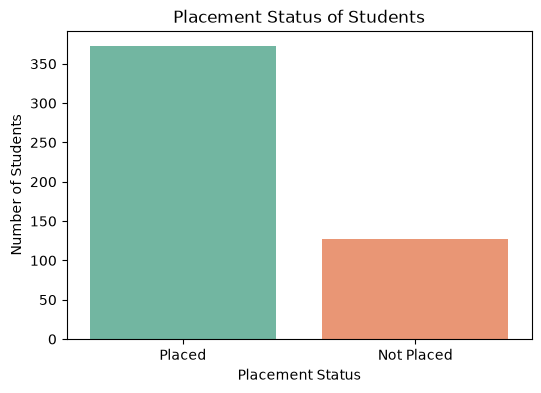

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="placement_status", palette="Set2")
plt.title("Placement Status of Students")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_8632\1125022917.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="placement_status", y="cgpa", palette="Set2")


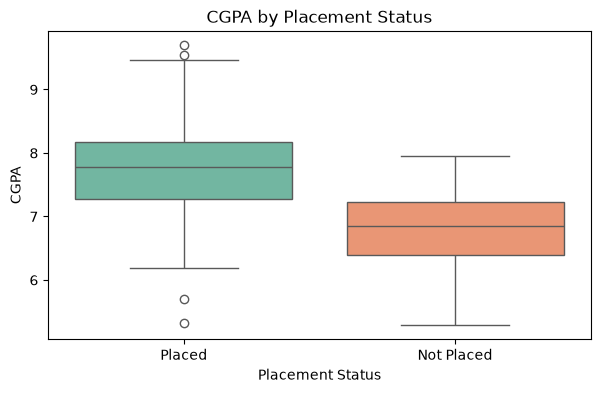

In [21]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="placement_status", y="cgpa", palette="Set2")
plt.title("CGPA by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")
plt.show()

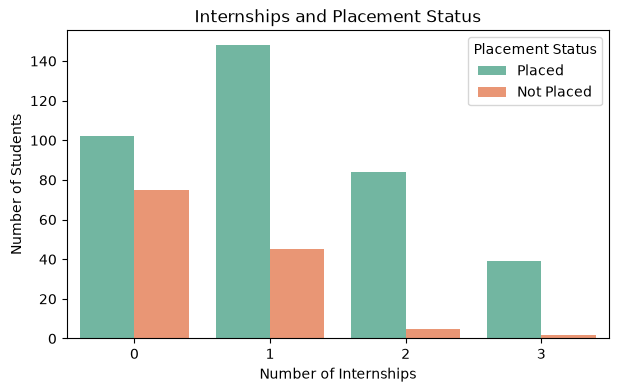

In [22]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="internship_count", hue="placement_status", palette="Set2")
plt.title("Internships and Placement Status")
plt.xlabel("Number of Internships")
plt.ylabel("Number of Students")
plt.legend(title="Placement Status")
plt.show()

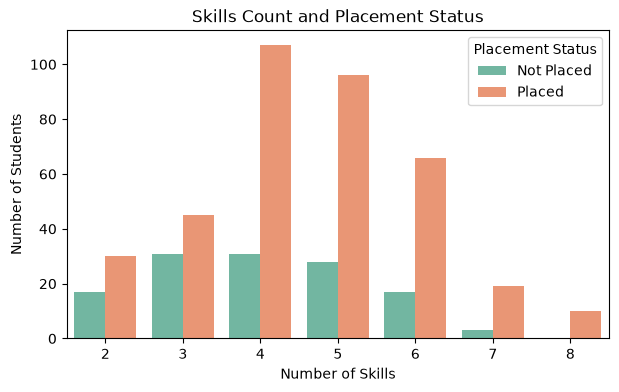

In [24]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="skills_count", hue="placement_status", palette="Set2")
plt.title("Skills Count and Placement Status")
plt.xlabel("Number of Skills")
plt.ylabel("Number of Students")
plt.legend(title="Placement Status")
plt.show()

In [25]:
df.groupby("placement_status")["skills_count"].mean()

placement_status
Not Placed    4.047244
Placed        4.589812
Name: skills_count, dtype: float64

In [26]:
df.groupby("placement_status")["internship_count"].mean()

placement_status
Not Placed    0.480315
Placed        1.160858
Name: internship_count, dtype: float64

In [29]:
df["branch"] = (
    df["branch"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df["branch"].unique()

array(['IT', 'CSE', 'EEE', 'ECE', 'MECH'], dtype=object)

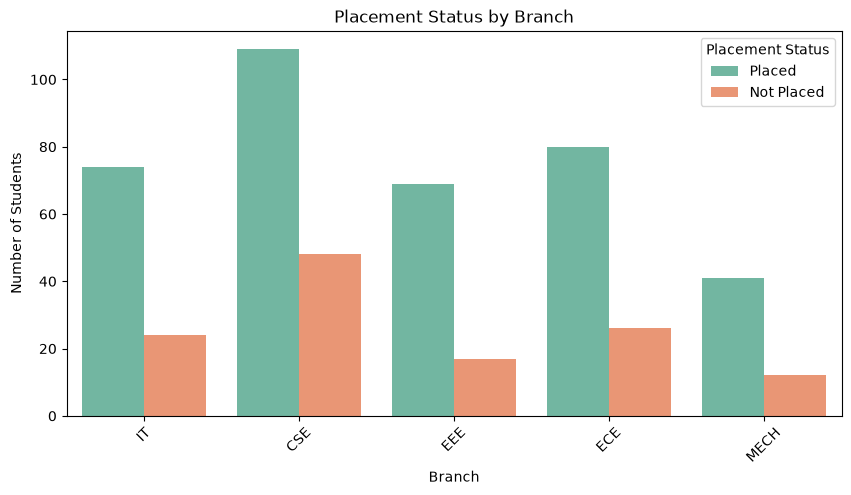

In [30]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="branch", hue="placement_status", palette="Set2")
plt.title("Placement Status by Branch")
plt.xlabel("Branch")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.legend(title="Placement Status")
plt.show()

In [31]:
branch_placement = (
    df.groupby("branch")["placement_status"]
    .value_counts(normalize=True)
    .unstack()
    .fillna(0) * 100
)

branch_placement

placement_status,Not Placed,Placed
branch,,
CSE,30.573248,69.426752
ECE,24.528302,75.471698
EEE,19.767442,80.232558
IT,24.489796,75.510204
MECH,22.641509,77.358491


In [32]:
branch_placement["Placed"].sort_values(ascending=False)

branch
EEE     80.232558
MECH    77.358491
IT      75.510204
ECE     75.471698
CSE     69.426752
Name: Placed, dtype: float64

In [33]:
df["primary_skill"] = (
    df["primary_skill"]
    .astype(str)
    .str.strip()
    .str.title()
)

df["primary_skill"].unique()

array(['Sql', 'Cybersecurity', 'Cloud Computing', 'Unknown',
       'Web Development', 'Java', 'Data Analysis', 'Machine Learning',
       'Python'], dtype=object)

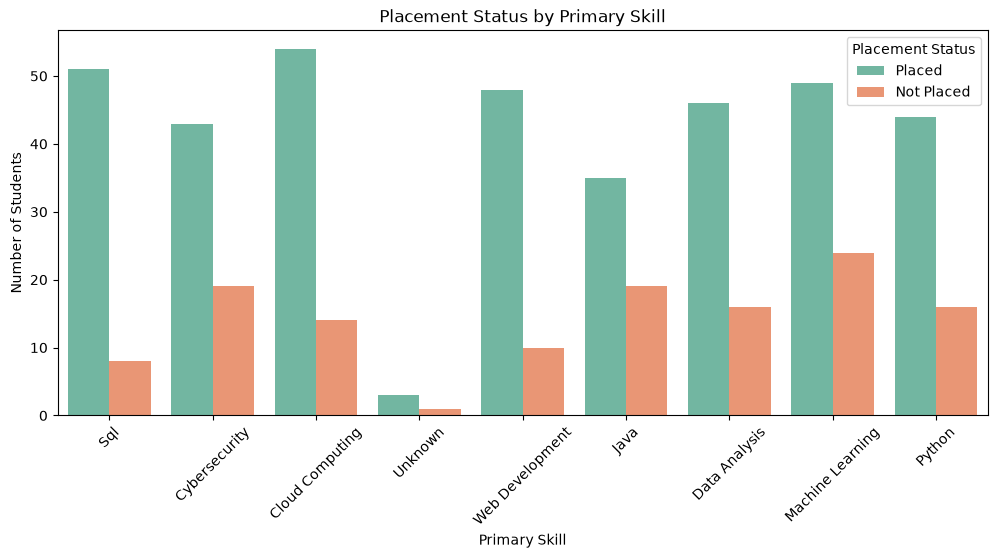

In [35]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="primary_skill", hue="placement_status", palette="Set2")
plt.title("Placement Status by Primary Skill")
plt.xlabel("Primary Skill")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.legend(title="Placement Status")
plt.show()

In [36]:
skill_placement = (
    df.groupby("primary_skill")["placement_status"]
    .value_counts(normalize=True)
    .unstack()
    .fillna(0) * 100
)

skill_placement

placement_status,Not Placed,Placed
primary_skill,,
Cloud Computing,20.588235,79.411765
Cybersecurity,30.645161,69.354839
Data Analysis,25.806452,74.193548
Java,35.185185,64.814815
Machine Learning,32.876712,67.123288
Python,26.666667,73.333333
Sql,13.559322,86.440678
Unknown,25.000000,75.000000
Web Development,17.241379,82.758621


In [37]:
skill_placement["Placed"].sort_values(ascending=False)

primary_skill
Sql                 86.440678
Web Development     82.758621
Cloud Computing     79.411765
Unknown             75.000000
Data Analysis       74.193548
Python              73.333333
Cybersecurity       69.354839
Machine Learning    67.123288
Java                64.814815
Name: Placed, dtype: float64

In [39]:
placed_df = df[df["placement_status"] == "Placed"]

placed_df.shape

(373, 11)

In [40]:
placed_df["package_lpa"].describe()

count    371.000000
mean       8.092803
std        1.241340
min        5.020000
25%        7.165000
50%        7.970000
75%        8.970000
max       12.110000
Name: package_lpa, dtype: float64

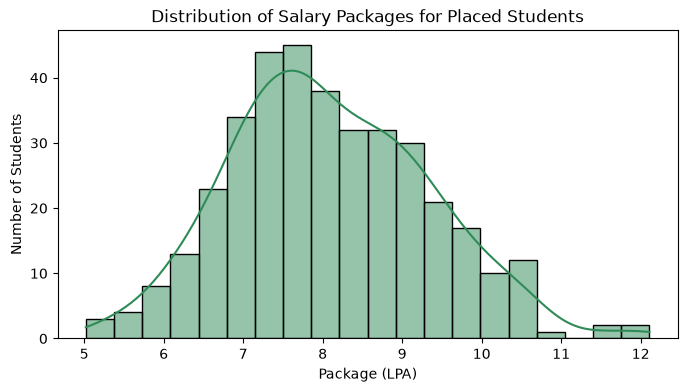

In [41]:
plt.figure(figsize=(8, 4))
sns.histplot(data=placed_df, x="package_lpa", bins=20, kde=True, color="seagreen")
plt.title("Distribution of Salary Packages for Placed Students")
plt.xlabel("Package (LPA)")
plt.ylabel("Number of Students")
plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_8632\2873850066.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=placed_df, x="primary_skill", y="package_lpa", palette="Set2")


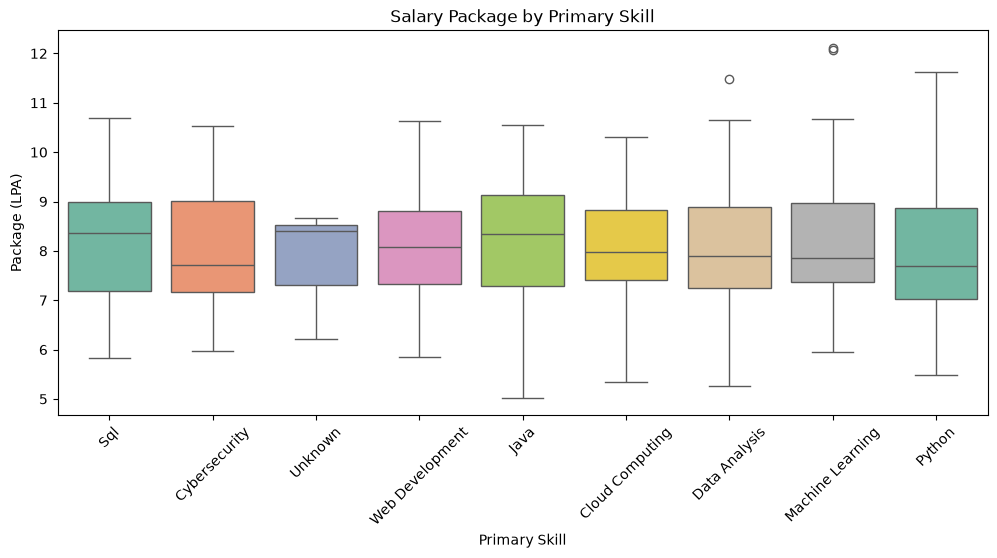

In [42]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=placed_df, x="primary_skill", y="package_lpa", palette="Set2")
plt.title("Salary Package by Primary Skill")
plt.xlabel("Primary Skill")
plt.ylabel("Package (LPA)")
plt.xticks(rotation=45)
plt.show()

In [45]:
df["location"] = (
    df["location"]
    .astype(str)
    .str.strip()
    .str.title()
)

df["location"].unique()

array(['Bangalore', 'Chennai', 'Nan', 'Pune', 'Hyderabad', 'Noida',
       'Coimbatore', 'Unknown'], dtype=object)

In [46]:
placed_df = df[df["placement_status"] == "Placed"]

placed_df["location"].value_counts()

location
Pune          71
Bangalore     66
Coimbatore    63
Hyderabad     59
Noida         58
Chennai       54
Unknown        2
Name: count, dtype: int64

C:\Users\admin\AppData\Local\Temp\ipykernel_8632\845528862.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


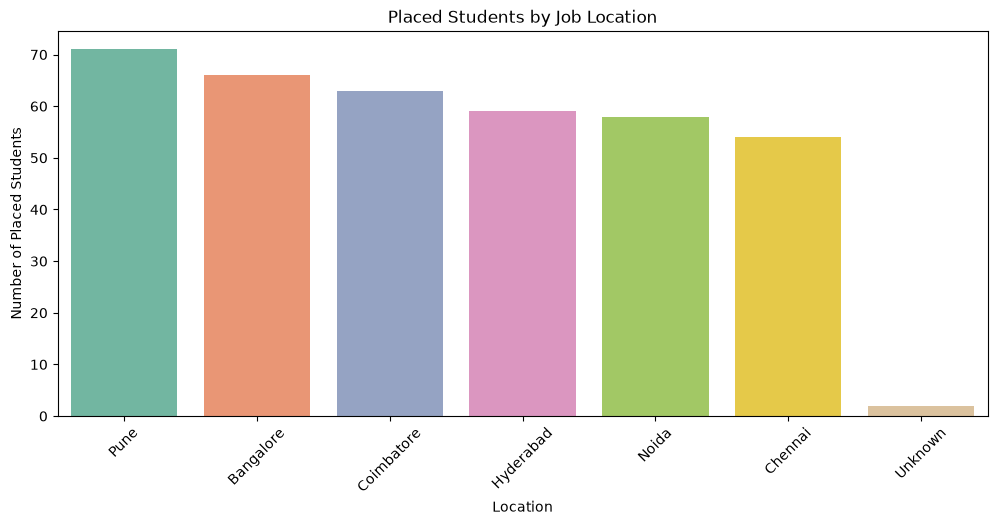

In [47]:
plt.figure(figsize=(12, 5))
sns.countplot(
    data=placed_df,
    x="location",
    order=placed_df["location"].value_counts().index,
    palette="Set2"
)
plt.title("Placed Students by Job Location")
plt.xlabel("Location")
plt.ylabel("Number of Placed Students")
plt.xticks(rotation=45)
plt.show()

In [48]:
placed_df.groupby("location")["package_lpa"].mean().sort_values(ascending=False)

location
Noida         8.243621
Coimbatore    8.127619
Hyderabad     8.072034
Pune          8.063099
Bangalore     8.041667
Chennai       8.014444
Unknown            NaN
Name: package_lpa, dtype: float64

In [49]:
df.to_csv("Student_Placement_Data_Final_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [50]:
total_students = len(df)
placed_students = (df["placement_status"] == "Placed").sum()
not_placed_students = (df["placement_status"] == "Not Placed").sum()
placement_rate = placed_students / total_students * 100

average_cgpa = df["cgpa"].mean()
placed_cgpa = df[df["placement_status"] == "Placed"]["cgpa"].mean()
not_placed_cgpa = df[df["placement_status"] == "Not Placed"]["cgpa"].mean()

average_package = df[df["placement_status"] == "Placed"]["package_lpa"].mean()

print("TOTAL STUDENTS:", total_students)
print("PLACED STUDENTS:", placed_students)
print("NOT PLACED STUDENTS:", not_placed_students)
print("PLACEMENT RATE:", round(placement_rate, 2), "%")
print("AVERAGE CGPA:", round(average_cgpa, 2))
print("AVERAGE CGPA - PLACED:", round(placed_cgpa, 2))
print("AVERAGE CGPA - NOT PLACED:", round(not_placed_cgpa, 2))
print("AVERAGE PACKAGE (PLACED):", round(average_package, 2), "LPA")

TOTAL STUDENTS: 500
PLACED STUDENTS: 373
NOT PLACED STUDENTS: 127
PLACEMENT RATE: 74.6 %
AVERAGE CGPA: 7.51
AVERAGE CGPA - PLACED: 7.76
AVERAGE CGPA - NOT PLACED: 6.77
AVERAGE PACKAGE (PLACED): 8.09 LPA


In [2]:
import pandas as pd

df = pd.read_csv("Student_Placement_Data_Final_Cleaned.csv")

df.head()

,student_id,branch,cgpa,internship_count,skills_count,primary_skill,placement_status,company,package_lpa,location,graduation_year
0,STU001,IT,8.13,0,5,Sql,Placed,TCS,6.26,Bangalore,2026
1,STU002,CSE,7.60,1,5,Cybersecurity,Placed,Tech Mahindra,7.32,Chennai,2026
2,STU003,EEE,7.95,0,3,Cloud Computing,Not Placed,NaN,NaN,Nan,2026
3,STU004,ECE,8.21,1,4,Unknown,Placed,HCL,8.40,Pune,2026
4,STU005,CSE,7.20,2,4,Web Development,Placed,TCS,8.66,Hyderabad,2026


In [3]:
mysql_df = df.copy()

mysql_df["cgpa"] = mysql_df["cgpa"].astype(object).where(mysql_df["cgpa"].notna(), "NULL")
mysql_df["package_lpa"] = mysql_df["package_lpa"].astype(object).where(mysql_df["package_lpa"].notna(), "NULL")
mysql_df["company"] = mysql_df["company"].fillna("NULL")
mysql_df["location"] = mysql_df["location"].fillna("NULL")

mysql_df.to_csv("Student_Placement_Data_MySQL.csv", index=False)

print("MySQL-ready CSV saved successfully.")

MySQL-ready CSV saved successfully.
